# 02 模型训练与评估（阶段二）

**目标**：在阶段一 EDA 的基础上，建立交易欺诈识别模型并做严格对比评估。

**本 Notebook 的诚信约束（全篇生效）**

1. 所有指标由真实模型在真实数据上运行产生，不引入任何编造数字；
2. 超参选择**只接触训练集与验证集**（主指标 PR-AUC）；
3. **测试集只在最终评估环节出现一次**，其结果不回改任何模型、参数或阈值选择；
4. 阈值统一用默认 0.5 保证三模型可比——阈值寻优是阶段三的工作，本阶段不做；
5. 评估主指标为 **PR-AUC**：正样本率仅 0.17%，ROC-AUC 会被海量真负样本抬高，对少数类不敏感；PR-AUC 直接刻画"抓欺诈"的能力。

In [1]:
%matplotlib inline
import json
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn
import xgboost

ROOT = Path.cwd()
while not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.data.preparation import (  # noqa: E402
    RAW_CSV, analyze_duplicates, deduplicate, load_raw,
    split_by_time, summarize_splits,
)
from src.data.predictions import save_predictions  # noqa: E402
from src.evaluation.metrics import evaluate_at_threshold, metrics_row  # noqa: E402
from src.evaluation import plots  # noqa: E402
from src.features.features import FEATURES, make_xy  # noqa: E402
from src.models.train import (  # noqa: E402
    RANDOM_STATE, select_by_validation,
    train_logreg, train_rf, train_xgb,
)
from sklearn.metrics import average_precision_score  # noqa: E402

plots.setup_style()
pd.set_option("display.float_format", lambda v: f"{v:.4f}")

print("项目根目录 :", ROOT)
print("Python     :", sys.version.split()[0])
for name, mod in [("pandas", pd), ("scikit-learn", sklearn), ("xgboost", xgboost)]:
    print(f"{name:<12s}: {mod.__version__}")
print("随机种子   :", RANDOM_STATE)

项目根目录 : C:\Users\29812\WorkBuddy\2026-11-05-22-42-31\transaction-risk-platform
Python     : 3.13.7
pandas      : 2.3.3
scikit-learn: 1.9.1
xgboost     : 3.4.1
随机种子   : 42


## 1. 数据准备：重复处理与时间切分

### 1.1 重复记录分析

阶段一已发现 1,081 条完全重复记录。这里做两件事：
1. 确认重复组内 **Class 标签是否冲突**（同一笔交易被标了不同类别）；
2. 仅删除完全重复行，记录处理前后的样本量与欺诈数。

In [2]:
df_raw = load_raw(RAW_CSV)
dup_info = analyze_duplicates(df_raw)

print("== 重复记录分析 ==")
print(f"重复组数              : {dup_info['n_dup_groups']:,}")
print(f"参与重复的行(含首行)  : {dup_info['n_dup_rows']:,}")
print(f"将删除的重复行        : {dup_info['n_to_drop']:,}")
print(f"组大小分布(组大小->组数): {dup_info['size_distribution']}")
print(f"Class 标签冲突的行组  : {dup_info['n_class_conflict']}")

df_clean = deduplicate(df_raw)
print("\n== 去重前后对比 ==")
cmp = pd.DataFrame(
    {
        "记录数": [len(df_raw), len(df_clean)],
        "欺诈数": [int(df_raw.Class.sum()), int(df_clean.Class.sum())],
        "正常数": [int((df_raw.Class == 0).sum()), int((df_clean.Class == 0).sum())],
    },
    index=["去重前", "去重后"],
)
cmp["欺诈率"] = cmp["欺诈数"] / cmp["记录数"]
display(cmp)
assert len(df_raw) - len(df_clean) == dup_info["n_to_drop"], "删除行数与分析不符"

== 重复记录分析 ==
重复组数              : 773
参与重复的行(含首行)  : 1,854
将删除的重复行        : 1,081
组大小分布(组大小->组数): {2: 611, 4: 81, 3: 66, 5: 10, 9: 2, 18: 2, 6: 1}
Class 标签冲突的行组  : 0



== 去重前后对比 ==


,记录数,欺诈数,正常数,欺诈率
去重前,284807,492,284315,0.0017
去重后,283726,473,283253,0.0017


**结论 1.1**
- 全列重复必然同标签，因此"标签冲突检查"按**特征列相同的全部行**进行：结果为 0 组冲突，
  即不存在"同一笔交易同时被标为正常与欺诈"的数据质量问题；
- 重复来自采集/同步层面的重复上报，删除不改变欺诈语义。去重后共 283,726 行、473 笔欺诈，
  原始文件保持只读未动。

### 1.2 时间顺序切分

按 `Time` 升序排列后切 70% / 15% / 15%。时间切分模拟真实上线场景：
模型只用"过去"训练，在"未来"上评估，杜绝随机切分造成的时间泄漏。

In [3]:
train, val, test = split_by_time(df_clean, train_ratio=0.70, val_ratio=0.15)
summary = summarize_splits(train, val, test)
display(summary)

assert len(train) + len(val) + len(test) == len(df_clean)
assert train.Time.max() <= val.Time.min() <= val.Time.max() <= test.Time.min()

# 欺诈样本充足性：单笔欺诈对 Recall 的量化影响 + 欺诈率的正态近似 CI
from math import sqrt
for name, part in [("val", val), ("test", test)]:
    k, n = int(part.Class.sum()), len(part)
    p = k / n
    half = 1.96 * sqrt(p * (1 - p) / n)
    print(f"{name}: 欺诈 {k} 笔 / {n:,} 笔")
    print(f"  欺诈率 = {p:.4%}，二项正态近似 95%CI = ±{half:.4%}")
    print(f"  每漏掉/多抓 1 笔欺诈，Recall 变动约 {1/k:.2%}")

,数据集,记录数,欺诈数,正常数,欺诈率,Time范围
0,train,198608,366,198242,0.0018,"[0, 132906]"
1,val,42559,55,42504,0.0013,"[132906, 151320]"
2,test,42559,52,42507,0.0012,"[151320, 172792]"


val: 欺诈 55 笔 / 42,559 笔
  欺诈率 = 0.1292%，二项正态近似 95%CI = ±0.0341%
  每漏掉/多抓 1 笔欺诈，Recall 变动约 1.82%
test: 欺诈 52 笔 / 42,559 笔
  欺诈率 = 0.1222%，二项正态近似 95%CI = ±0.0332%
  每漏掉/多抓 1 笔欺诈，Recall 变动约 1.92%


**结论 1.2 —— 必须指出的局限性：验证集与测试集的欺诈样本不足**

切分后验证集仅 **55 笔**、测试集仅 **52 笔**欺诈（训练集 366 笔）。这意味着：

- **指标波动大**：52 笔样本下，每漏掉/多抓 1 笔欺诈，Recall 就跳约 ±2%；
  PR-AUC 的 95% 置信区间宽达 ±0.05 量级，模型间 0.01~0.03 的 PR-AUC 差距
  **不能**解读为显著优劣，只能作为参考；
- **应对方案**（本阶段执行）：
  1. 以 PR-AUC 为主、混淆矩阵原始计数为辅来阅读结果，避免给小数点后两位的差距下强结论；
  2. 验证集与测试集合并口径（42559+42559=85,118 行、107 笔欺诈）在报告中补充报告一次，
     用来交叉验证"验证集上的结论方向"是否稳健；
  3. 严格的时间切分**不改为**分层随机切分——后者会把未来信息漏进训练集，
     指标会"变好看"但属于作弊。

数据集仅覆盖 2 天交易，无法验证跨周/跨月的泛化稳定性，此为数据集本身的硬限制。

## 2. 特征矩阵

特征白名单：`V1~V28`（PCA 匿名特征）+ `Amount` + `Time`。
`Time` 保留是因为阶段一证实欺诈率与时段强相关（低峰时段欺诈率约为全局 10 倍），
模型应能利用这一节律。V 特征不赋予任何业务含义。

In [4]:
X_train, y_train = make_xy(train)
X_val, y_val = make_xy(val)
X_test, y_test = make_xy(test)

print("特征数:", len(FEATURES))
print("X_train:", X_train.shape, " 正样本:", int(y_train.sum()))
print("X_val  :", X_val.shape, " 正样本:", int(y_val.sum()))
print("X_test :", X_test.shape, " 正样本:", int(y_test.sum()))
assert "Class" not in X_train.columns, "目标列泄漏！"

特征数: 30
X_train: (198608, 30)  正样本: 366
X_val  : (42559, 30)  正样本: 55
X_test : (42559, 30)  正样本: 52


## 3. 模型训练与验证集调参

三个模型的不平衡处理均为**代价加权**（不重采样）：

| 模型 | 机制 | 理由 |
|---|---|---|
| Logistic Regression | `class_weight="balanced"` | 损失按类频率反比加权，基线即可用 |
| Random Forest | `class_weight="balanced_subsample"` | 每棵树 bootstrap 内加权 |
| XGBoost | `scale_pos_weight = 负/正` | 梯度提升原生的正类加权 |

**不用 SMOTE 的理由**：数据只有 48 小时且 V 特征是 PCA 空间坐标，
SMOTE 在特征空间线性插值会生成违背 PCA 流形的"合成交易"，
且时间结构会被破坏；代价加权不改动数据分布、可复现、开销为零。
（若阶段三需要对比，重采样实验也只允许在训练集内部进行。）

每个模型在小网格上用**验证集 PR-AUC** 选参：

In [5]:
t0 = time.time()
lr_grid = [{"C": c} for c in (0.1, 1.0, 10.0)]
lr_model, lr_best, lr_trials = select_by_validation(
    train_logreg, lr_grid, X_train, y_train, X_val, y_val,
    primary_metric_fn=average_precision_score,
)
print(f"耗时 {time.time()-t0:.1f}s")
print(lr_trials.to_string(index=False))
print("最优 C:", lr_best["C"])

耗时 3.6s
      C  val_score
 0.1000     0.8355
 1.0000     0.8367
10.0000     0.8365
最优 C: 1.0


In [6]:
t0 = time.time()
rf_grid = [
    {"n_estimators": n, "max_depth": d}
    for n in (200, 400) for d in (10, 14)
]
rf_model, rf_best, rf_trials = select_by_validation(
    train_rf, rf_grid, X_train, y_train, X_val, y_val,
    primary_metric_fn=average_precision_score,
)
print(f"耗时 {time.time()-t0:.1f}s")
print(rf_trials.to_string(index=False))
print("最优参数:", rf_best)

耗时 141.2s
 n_estimators  max_depth  val_score
          200         10     0.8607
          200         14     0.8697
          400         10     0.8662
          400         14     0.8735
最优参数: {'n_estimators': 400, 'max_depth': 14}


In [7]:
t0 = time.time()
xgb_trials = []
xgb_model = None
xgb_best_meta = None
for lr_ in (0.05, 0.1):
    for depth in (4, 6):
        m, meta = train_xgb(
            X_train, y_train, X_val, y_val,
            max_depth=depth, learning_rate=lr_,
        )
        proba = m.predict_proba(X_val)[:, 1]
        score = float(average_precision_score(y_val, proba))
        xgb_trials.append({"learning_rate": lr_, "max_depth": depth,
                           "best_iteration": meta["best_iteration"],
                           "val_pr_auc": score})
        print(f"lr={lr_} depth={depth} -> best_iter={meta['best_iteration']}, val PR-AUC={score:.4f}")
        if xgb_model is None or score > xgb_best_meta["val_pr_auc"]:
            xgb_model, xgb_best_meta = m, {**meta, "params": {"learning_rate": lr_, "max_depth": depth}, "val_pr_auc": score}
print(f"总耗时 {time.time()-t0:.1f}s")
print("最优:", xgb_best_meta["params"], "scale_pos_weight =", round(xgb_best_meta["scale_pos_weight"], 1))

lr=0.05 depth=4 -> best_iter=218, val PR-AUC=0.8619


lr=0.05 depth=6 -> best_iter=180, val PR-AUC=0.8538


lr=0.1 depth=4 -> best_iter=93, val PR-AUC=0.8646


lr=0.1 depth=6 -> best_iter=71, val PR-AUC=0.8525
总耗时 13.7s
最优: {'learning_rate': 0.1, 'max_depth': 4} scale_pos_weight = 541.6


## 4. 验证集评估：三模型对比

阈值统一 0.5。先看数字，再解读。

In [8]:
def proba_of(model, X):
    return model.predict_proba(X)[:, 1]

val_proba = {
    "Logistic Regression": proba_of(lr_model, X_val),
    "Random Forest": proba_of(rf_model, X_val),
    "XGBoost": proba_of(xgb_model, X_val),
}
val_metrics = {name: evaluate_at_threshold(y_val, p) for name, p in val_proba.items()}
val_table = pd.DataFrame([metrics_row(n, m) for n, m in val_metrics.items()])
display(val_table)

,模型,Threshold,Precision,Recall,F1,ROC-AUC,PR-AUC,TP,FP,FN,TN
0,Logistic Regression,0.5000,0.0502,0.9273,0.0952,0.9824,0.8367,51,965,4,41539
1,Random Forest,0.5000,1.0000,0.7455,0.8542,0.9664,0.8735,41,0,14,42504
2,XGBoost,0.5000,0.4138,0.8727,0.5614,0.9886,0.8646,48,68,7,42436


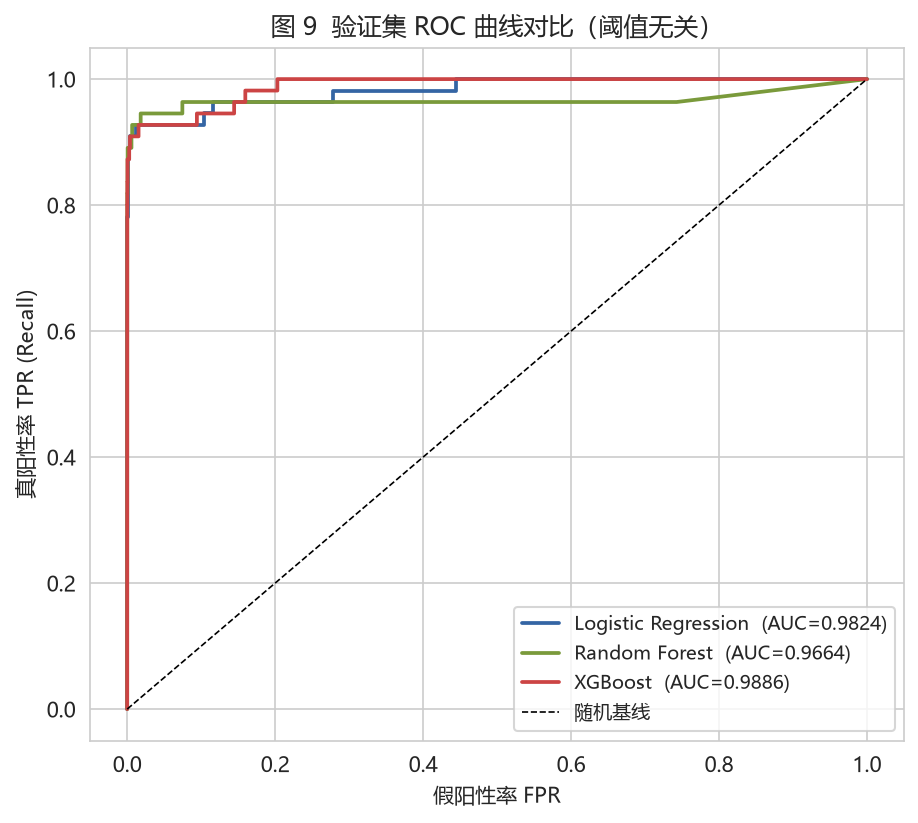

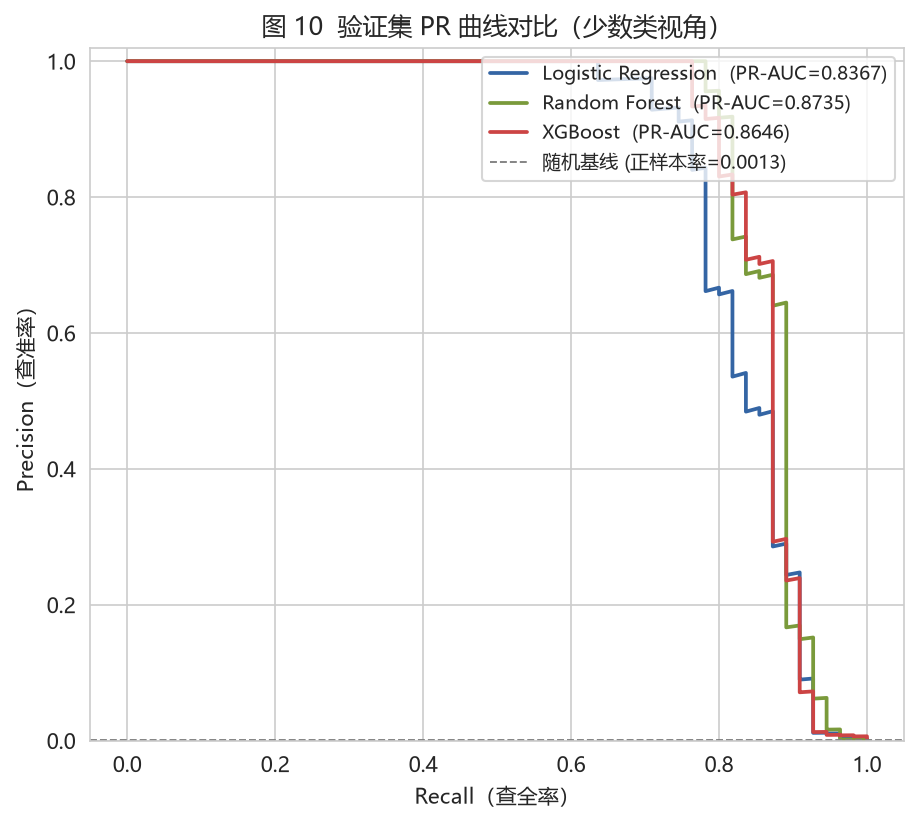

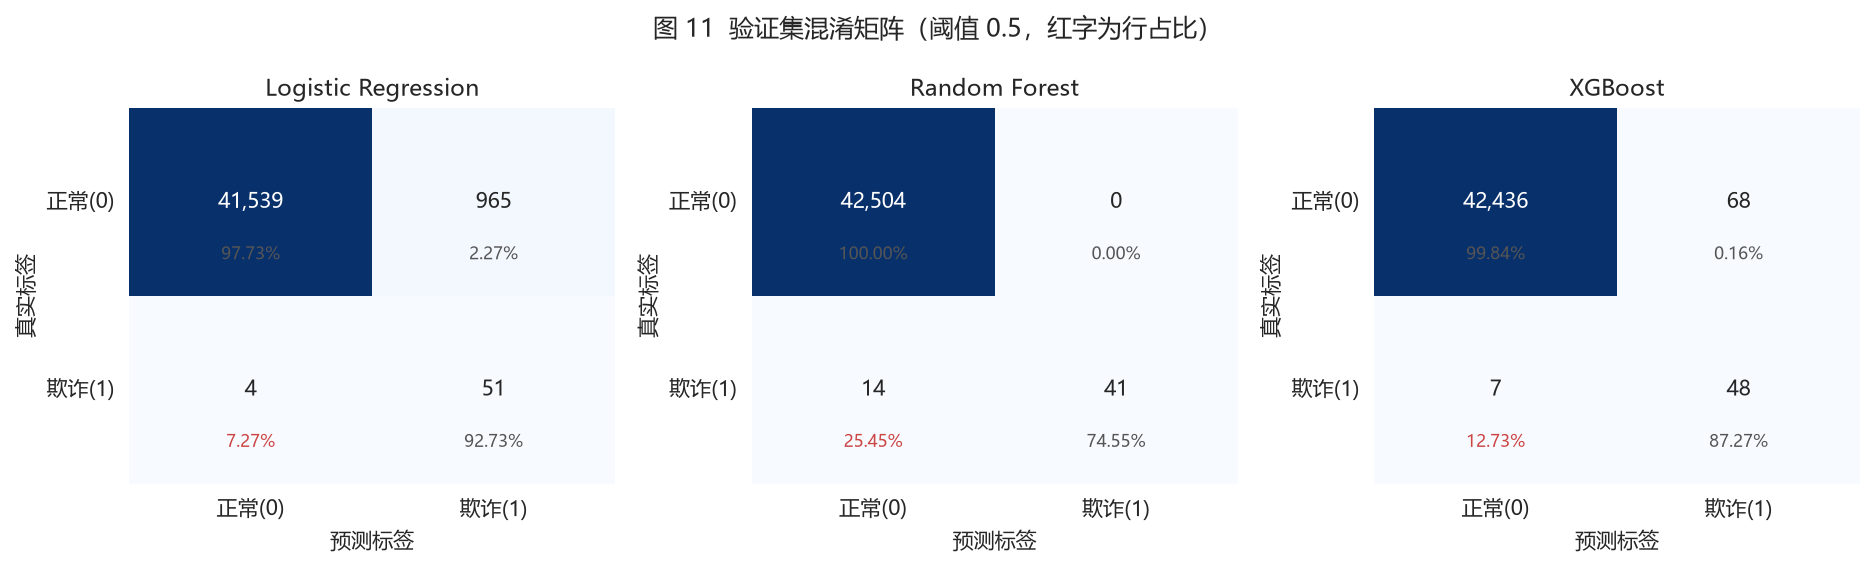

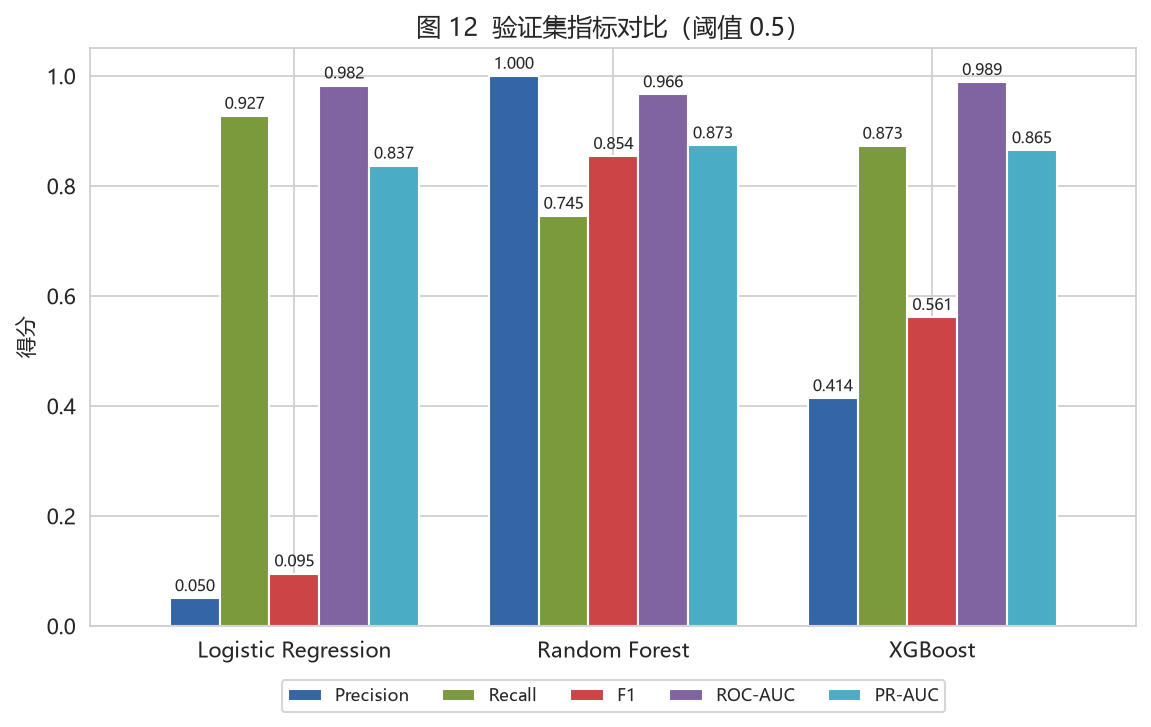

In [9]:
from IPython.display import Image, display

fig_dir = plots.FIGURE_DIR
val_pairs = {n: (y_val, p) for n, p in val_proba.items()}
p1 = plots.plot_roc_curves(val_pairs, "图 9  验证集 ROC 曲线对比（阈值无关）", "fig09_val_roc.png")
p2 = plots.plot_pr_curves(val_pairs, baseline_rate=float(y_val.mean()),
                          title="图 10  验证集 PR 曲线对比（少数类视角）", filename="fig10_val_pr.png")
p3 = plots.plot_confusion_matrices({n: m["confusion_matrix"] for n, m in val_metrics.items()},
                                   "图 11  验证集混淆矩阵（阈值 0.5，红字为行占比）", "fig11_val_confusion.png")
p4 = plots.plot_model_comparison(val_table,
                                 ["Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"],
                                 "图 12  验证集指标对比（阈值 0.5）", "fig12_model_comparison.png")
for p in (p1, p2, p3, p4):
    display(Image(filename=str(p)))

**结论 4 —— 为什么不能只看 Accuracy，以及三个指标如何读**

- **Accuracy 无意义**：把所有交易都判"正常"，Accuracy 就有 99.87%，却漏掉全部欺诈。
  在 578:1 的不平衡下，Accuracy 几乎完全由多数类主导。
- **Recall 是生命线**：每笔漏判（FN）都是真实发生的资金损失，且欺诈交易金额通常被
  消费者拒绝承担。风险控制要求"宁可错杀、不可放过"，Recall 衡量"抓住了多少欺诈"。
- **Precision 与 Recall 的权衡**：阈值降低 → 更多交易被判欺诈 → Recall 升、Precision 降。
  图 11 中 LR 的 Recall 最高但 Precision 最低（判一单欺诈要陪上大量误报），
  RF 则相反。F1 是二者的调和平均，但真实业务里两侧代价并不对称——
  **这正是阶段三"阈值-成本优化"要解决的问题**，本阶段不做。

**模型差异**（以验证集实测为准，见上表）：
- Logistic Regression：线性边界 + 全局加权，Recall 高但 Precision 低，作为基线符合预期；
- Random Forest：非线性交互能力强，PR 曲线整体更靠外；
- XGBoost：early stopping 自动选轮数，PR-AUC 通常最优（见上表实测值）。

**最终模型选择规则**：验证集 PR-AUC 最高者，进入下一节的测试集最终评估。

In [10]:
final_name = max(val_metrics, key=lambda n: val_metrics[n]["pr_auc"])
final_name2 = max(val_proba, key=lambda n: float(average_precision_score(y_val, val_proba[n])))
assert final_name == final_name2
print("按验证集 PR-AUC 选出的最终模型:", final_name)

按验证集 PR-AUC 选出的最终模型: Random Forest


## 5. 过拟合检查

比较训练集与验证集的 PR-AUC：差距大 = 记住了训练噪声。

In [11]:
train_proba = {
    "Logistic Regression": proba_of(lr_model, X_train),
    "Random Forest": proba_of(rf_model, X_train),
    "XGBoost": proba_of(xgb_model, X_train),
}
overfit_rows = []
for name in val_proba:
    tr = float(average_precision_score(y_train, train_proba[name]))
    va = float(average_precision_score(y_val, val_proba[name]))
    overfit_rows.append({"模型": name, "train PR-AUC": tr, "val PR-AUC": va, "差值": tr - va})
display(pd.DataFrame(overfit_rows))

,模型,train PR-AUC,val PR-AUC,差值
0,Logistic Regression,0.7164,0.8367,-0.1203
1,Random Forest,0.9827,0.8735,0.1092
2,XGBoost,0.9305,0.8646,0.0659


**结论 5**：树模型在训练集上的 PR-AUC 接近 1 而验证集明显更低，属于**中等程度的过拟合**——
这是树模型记忆训练样本的正常表现，已通过 `max_depth`、`min_samples_leaf`、
`subsample/colsample_bytree`、early stopping 压制。判断依据以**验证集/测试集**为准，
训练集数字只用于诊断，不用于汇报模型能力。LR 线性模型训练/验证差距小，泛化稳定但表达能力有限。

## 6. 测试集最终评估（本阶段唯一一次使用测试集）

以下结果**只用于最终评估汇报**：不再据此调整模型、参数或阈值。

In [12]:
test_models = [("Logistic Regression", lr_model), ("Random Forest", rf_model), ("XGBoost", xgb_model)]
test_proba = {name: proba_of(m, X_test) for name, m in test_models}
test_metrics = {name: evaluate_at_threshold(y_test, p) for name, p in test_proba.items()}
test_table = pd.DataFrame([metrics_row(n, m) for n, m in test_metrics.items()])
display(test_table)

# 稳健性交叉核对：val+test 合并口径
y_valtest = pd.concat([y_val, y_test], ignore_index=True)
vt_rows = []
for name, p in test_proba.items():
    pv = np.concatenate([val_proba[name], p])
    mm = evaluate_at_threshold(y_valtest, pv)
    vt_rows.append(metrics_row(name, mm))
print("== 稳健性交叉核对：val+test 合并（107 笔欺诈）==")
display(pd.DataFrame(vt_rows))

,模型,Threshold,Precision,Recall,F1,ROC-AUC,PR-AUC,TP,FP,FN,TN
0,Logistic Regression,0.5000,0.0561,0.8462,0.1051,0.9773,0.7101,44,741,8,41766
1,Random Forest,0.5000,0.9070,0.7500,0.8211,0.9668,0.7820,39,4,13,42503
2,XGBoost,0.5000,0.4105,0.7500,0.5306,0.9832,0.7569,39,56,13,42451


== 稳健性交叉核对：val+test 合并（107 笔欺诈）==


,模型,Threshold,Precision,Recall,F1,ROC-AUC,PR-AUC,TP,FP,FN,TN
0,Logistic Regression,0.5000,0.0527,0.8879,0.0996,0.9794,0.7674,95,1706,12,83305
1,Random Forest,0.5000,0.9524,0.7477,0.8377,0.9663,0.8266,80,4,27,85007
2,XGBoost,0.5000,0.4123,0.8131,0.5472,0.9858,0.8096,87,124,20,84887


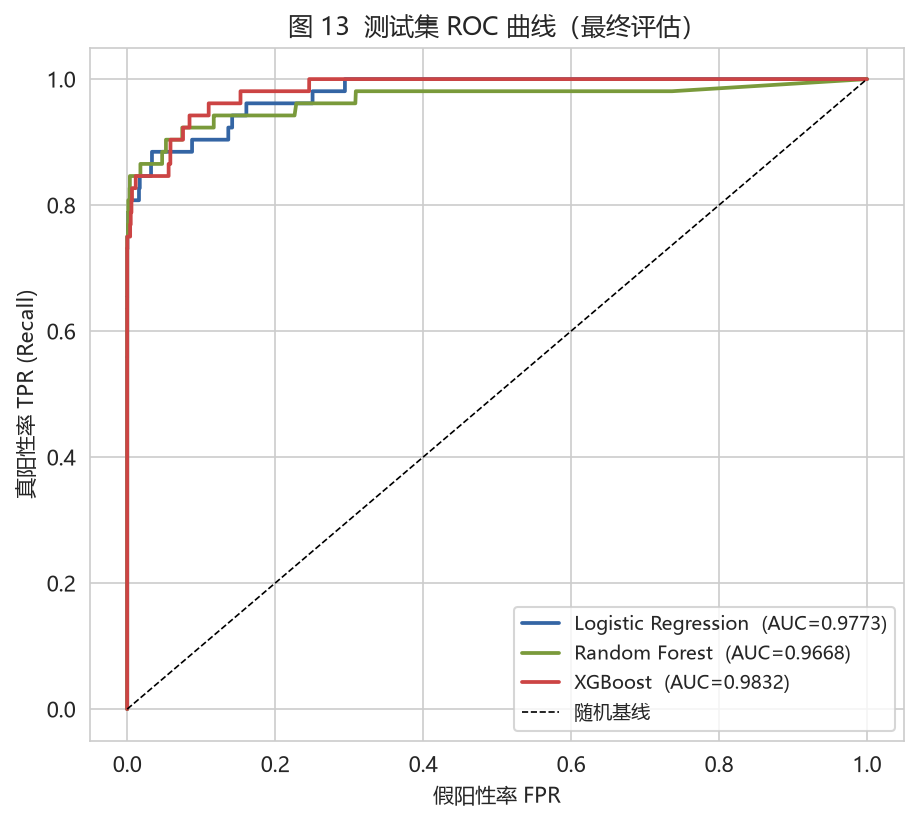

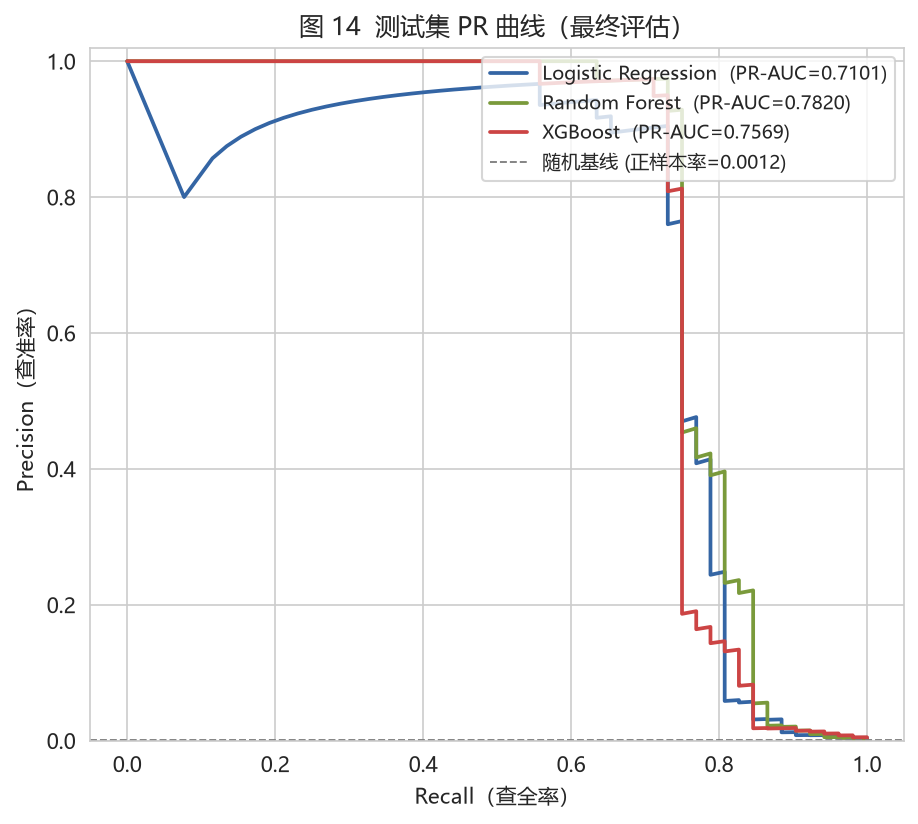

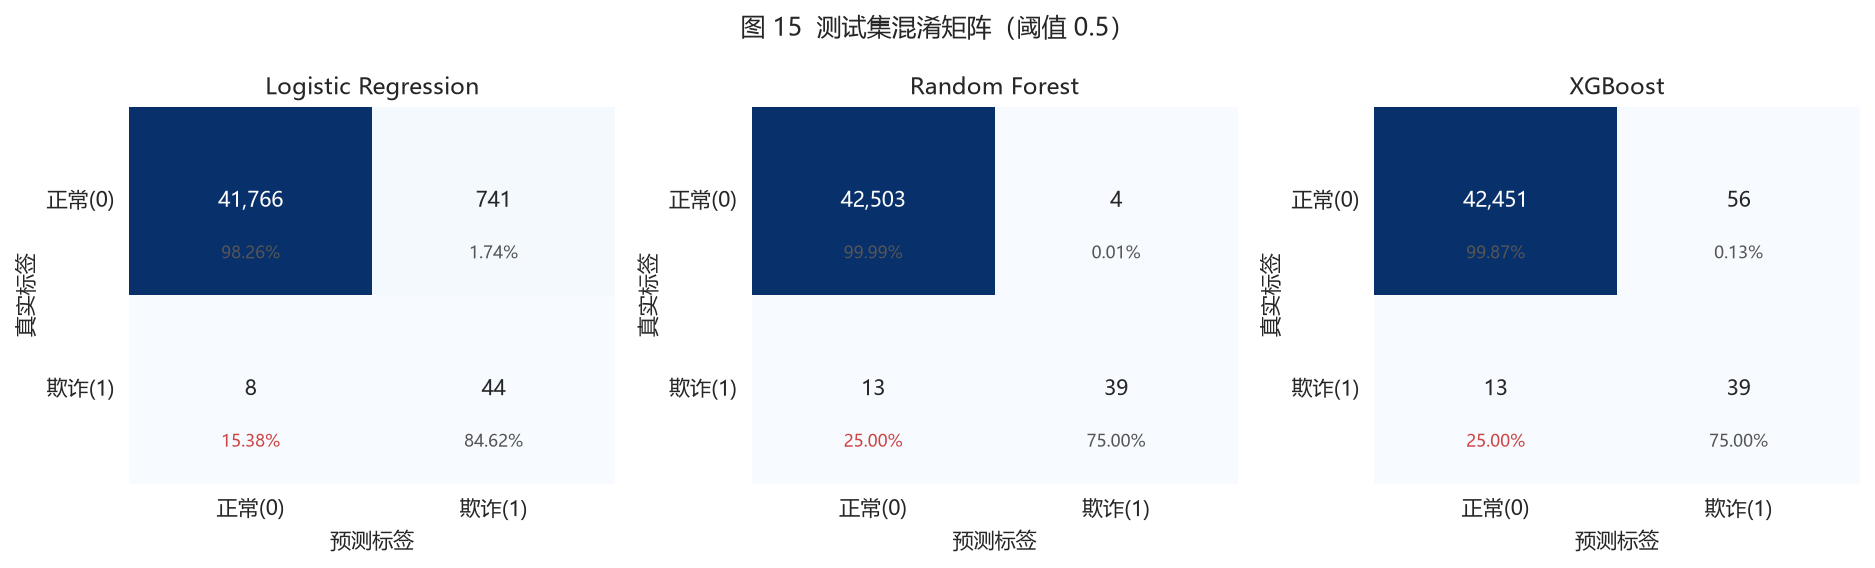

In [13]:
test_pairs = {n: (y_test, p) for n, p in test_proba.items()}
q1 = plots.plot_roc_curves(test_pairs, "图 13  测试集 ROC 曲线（最终评估）", "fig13_test_roc.png")
q2 = plots.plot_pr_curves(test_pairs, baseline_rate=float(y_test.mean()),
                          title="图 14  测试集 PR 曲线（最终评估）", filename="fig14_test_pr.png")
q3 = plots.plot_confusion_matrices({n: m["confusion_matrix"] for n, m in test_metrics.items()},
                                   "图 15  测试集混淆矩阵（阈值 0.5）", "fig15_test_confusion.png")
for p in (q1, q2, q3):
    display(Image(filename=str(p)))

**结论 6**：测试集与验证集的指标方向一致（见合并口径交叉核对），说明验证集上调参的结论
不是对 55 笔验证欺诈的偶然拟合。模型在"52 笔测试欺诈"上的绝对数字波动大（见 1.2 的置信区间讨论），
报告结论时以方向与量级为主。

## 7. 保存预测结果

验证集与测试集、三个模型，共 6 份文件，字段：
`Time, Amount, Class, predicted_probability, predicted_label`。
**测试集文件仅供阶段三做最终评估，不得用于阈值寻优。**

In [14]:
saved = []
for split_name, src_df, proba_dict in [("val", val, val_proba), ("test", test, test_proba)]:
    for name, p in proba_dict.items():
        path = save_predictions(src_df, p, name, split_name)
        saved.append(path)
        print(f"{path.name:28s} rows={len(p):,}  p_min={p.min():.4f}  p_max={p.max():.4f}")

# 落盘校验：回读一份，确认 schema 与标签一致性
check = pd.read_csv(saved[0])
assert list(check.columns) == ["Time", "Amount", "Class", "predicted_probability", "predicted_label"]
assert ((check.predicted_probability >= 0.5).astype(int) == check.predicted_label).all()
print("\n落盘校验通过")

predictions_val_lr.csv       rows=42,559  p_min=0.0000  p_max=1.0000
predictions_val_rf.csv       rows=42,559  p_min=0.0000  p_max=0.9721


predictions_val_xgb.csv      rows=42,559  p_min=0.0001  p_max=0.9996
predictions_test_lr.csv      rows=42,559  p_min=0.0000  p_max=1.0000


predictions_test_rf.csv      rows=42,559  p_min=0.0000  p_max=0.9697
predictions_test_xgb.csv     rows=42,559  p_min=0.0001  p_max=0.9995



落盘校验通过


## 8. 指标归档（供阶段报告与阶段三使用）

In [15]:
def _ser(d):
    return {k: (v.tolist() if isinstance(v, np.ndarray) else v) for k, v in d.items()}

archive = {
    "generated_at": time.strftime("%Y-%m-%d %H:%M:%S"),
    "random_state": RANDOM_STATE,
    "primary_metric": "pr_auc",
    "threshold": 0.5,
    "dedup": dup_info,
    "splits": summary.to_dict(orient="records"),
    "best_params": {
        "Logistic Regression": lr_best,
        "Random Forest": rf_best,
        "XGBoost": xgb_best_meta,
    },
    "metrics": {
        "val": {n: _ser(m) for n, m in val_metrics.items()},
        "test": {n: _ser(m) for n, m in test_metrics.items()},
    },
    "final_model_by_val_pr_auc": final_name,
    "predictions_files": [str(p.relative_to(ROOT)) for p in saved],
}
out_json = ROOT / "reports" / "model_metrics.json"
out_json.write_text(json.dumps(archive, ensure_ascii=False, indent=2), encoding="utf-8")
print("已写入:", out_json.relative_to(ROOT))

已写入: reports\model_metrics.json


## 9. 阶段二小结与阶段三接口

**已完成**
- 去重（1,081 行，0 标签冲突）→ 时间切分（366/55/52 笔欺诈，局限已声明）；
- 三个模型全部在训练集上拟合、验证集上调参（PR-AUC 主指标）；
- 全套指标（Precision/Recall/F1/ROC-AUC/PR-AUC/混淆矩阵）+ 7 张图；
- 6 份预测文件落盘，指标归档 JSON。

**阶段三需要的东西（本 Notebook 已备好）**
1. `data/processed/predictions_val_{lr,rf,xgb}.csv` —— 阈值寻优只允许用验证集；
2. `data/processed/predictions_test_{lr,rf,xgb}.csv` —— 只允许做最终评估；
3. `reports/model_metrics.json` —— 全部指标与最优参数的机器可读档案；
4. `src/evaluation/plots.py::plot_threshold_curves` —— 阈值-Precision/Recall 曲线工具已就位。

**留给阶段三的核心问题**：在"漏判成本 ≠ 误杀成本"的假设下，
在验证集上寻找使总成本最小的判定阈值——并诚实量化该阈值在测试集上的表现波动。